<a href="https://colab.research.google.com/github/AfraazUlHaque/data-analytics/blob/main/dbscan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Number of clusters: 2
Noise points: 2


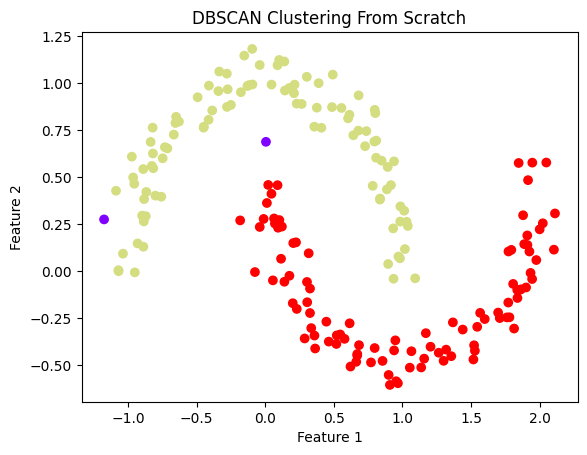

In [ ]:
import numpy as np
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
X, y = make_moons(n_samples=200, noise=0.08, random_state=42)

eps = 0.2
min_pts = 5


labels = [-1] * len(X)
visited = [False] * len(X)


def region_query(point):
    neighbors = []
    for i in range(len(X)):
        distance = np.linalg.norm(X[point] - X[i])
        if distance <= eps:
            neighbors.append(i)
    return neighbors


def expand_cluster(point, neighbors, cluster_id):
    labels[point] = cluster_id
    i = 0

    while i < len(neighbors):
        p = neighbors[i]

        if not visited[p]:
            visited[p] = True
            new_neighbors = region_query(p)

            if len(new_neighbors) >= min_pts:
                for n in new_neighbors:
                    if n not in neighbors:
                        neighbors.append(n)

        if labels[p] == -1:
            labels[p] = cluster_id

        i += 1


cluster_id = 0

for point in range(len(X)):
    if visited[point]:
        continue

    visited[point] = True
    neighbors = region_query(point)

    if len(neighbors) < min_pts:
        labels[point] = -1
    else:
        cluster_id += 1
        expand_cluster(point, neighbors, cluster_id)

print("Number of clusters:", len(set(labels) - {-1}))
print("Noise points:", labels.count(-1))


plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow")
plt.title("DBSCAN Clustering From Scratch")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
